# Cardiovascular Disease Prediction: Which Factors Matter Most?
**IE0005 Mini-Project** | Dataset: Kaggle *Cardiovascular Disease* (`cardio_train.csv`, 70,000 patients)

## Problem statement
Cardiovascular disease (CVD) is a leading cause of death worldwide and early screening is cheap if it relies only on routine measurements. We ask two questions:
1. **Prediction:** how well can routine measurements (age, body size, blood pressure, cholesterol, glucose, lifestyle) predict whether a patient has CVD?
2. **Explanation:** which *type* of factor drives those predictions: **immutable traits** (age, gender, height), **physiological vitals** (blood pressure, weight/BMI, cholesterol, glucose) or **lifestyle choices** (smoking, alcohol, activity)?

**Approach:** clean impossible values, engineer features (age in years, BMI, pulse pressure), compare a Decision Tree baseline with Logistic Regression, Random Forest (tuned with `RandomizedSearchCV`) and Gradient Boosting, then use a feature-group ablation and **SHAP** to explain the model.

In [1]:
# Basic Libraries
import numpy as np
import pandas as pd
import seaborn as sb
import shap
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve, recall_score

RANDOM_STATE = 42
sb.set_theme(style='whitegrid')

C:\Users\A Team\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Data Loading

In [2]:
df = pd.read_csv('cardio_train.csv', sep=';')
df.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [4]:
# Data-quality checks on the raw data
print("Missing values per column:\n", df.isna().sum().to_string())
print("\nDuplicate rows (ignoring id):", df.drop(columns='id').duplicated().sum())
print("Duplicate ids:", df['id'].duplicated().sum())

Missing values per column:
 id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0

Duplicate rows (ignoring id): 24
Duplicate ids: 0


# Data Cleaning

In [5]:
# Convert age from days to years
df['age_years'] = round(df['age'] / 365.25, 2)

# Calculate BMI (weight in kg / height in meters squared)
df['bmi'] = round(df['weight'] / ((df['height'] / 100) ** 2), 2)

# Calculate Pulse Pressure
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

# Clean Gender to binary (0 = Female, 1 = Male) for clearer SHAP interpretation
df['gender'] = df['gender'].map({1: 0, 2: 1})

# Filter physiologically impossible vitals, BMI, and Pulse Pressure
df_cleaned = df[
    (df['ap_hi'] >= 80) & (df['ap_hi'] <= 240) &
    (df['ap_lo'] >= 50) & (df['ap_lo'] <= 140) &
    (df['ap_hi'] > df['ap_lo']) &
    (df['pulse_pressure'] >= 20) & (df['pulse_pressure'] <= 120) & # Normal PP is around 40
    (df['height'] >= 130) & (df['height'] <= 210) &
    (df['weight'] >= 40) & (df['weight'] <= 180) &
    (df['bmi'] >= 15) & (df['bmi'] <= 55)
].copy()

print("Class Balance after cleaning:")
print(df_cleaned['cardio'].value_counts(normalize=True).round(3))

final_count = len(df_cleaned)
print(f"Final row count: {final_count}")
print(f"Rows dropped: {len(df) - final_count} ({round((len(df) - final_count)/len(df) * 100, 2)}%)")

display(df_cleaned[['age_years', 'bmi', 'ap_hi', 'ap_lo', 'pulse_pressure']].describe().round(2))

Class Balance after cleaning:
cardio
0    0.505
1    0.495
Name: proportion, dtype: float64
Final row count: 68341
Rows dropped: 1659 (2.37%)


,age_years,bmi,ap_hi,ap_lo,pulse_pressure
count,68341.00,68341.00,68341.00,68341.00,68341.00
mean,53.29,27.43,126.70,81.31,45.39
std,6.76,5.12,16.61,9.38,11.53
min,29.56,15.04,80.00,50.00,20.00
25%,48.34,23.88,120.00,80.00,40.00
50%,53.94,26.35,120.00,80.00,40.00
75%,58.38,30.12,140.00,90.00,50.00
max,64.92,54.97,240.00,140.00,120.00


The raw data contains impossible values: systolic BP up to 16,020 and as low as -150 mmHg, diastolic BP up to 11,000 mmHg, 1,236 rows where systolic is not higher than diastolic, a height of 55 cm and a weight of 10 kg. Applying physiologically plausible ranges removes 1,659 rows (2.37%) and leaves 68,341 rows. The classes stay balanced (50.5% no CVD / 49.5% CVD), so plain accuracy is a fair metric and no resampling is needed. After cleaning, the summary statistics are plausible (mean age 53.3 years, median BMI 26.4, median BP 120/80).

*Note:* the cut-offs are our own judgement calls (e.g. BMI 15-55). They are conservative and only drop clear data-entry errors, but a different range would change the row count slightly.

In [6]:
# ONE shared definition of feature groups, used by the heatmap, ablation study and SHAP
FEATURE_GROUPS = {
    'Immutable Traits':     ['age_years', 'gender', 'height'],
    'Physiological Vitals': ['weight', 'bmi', 'ap_hi', 'ap_lo', 'pulse_pressure', 'cholesterol', 'gluc'],
    'Lifestyle Choices':    ['smoke', 'alco', 'active'],
}
ALL_FEATURES = [f for cols in FEATURE_GROUPS.values() for f in cols]
CATEGORY_OF = {f: g for g, cols in FEATURE_GROUPS.items() for f in cols}

X = df_cleaned[ALL_FEATURES]
y = df_cleaned['cardio']
print(len(ALL_FEATURES), "features:", ALL_FEATURES)

13 features: ['age_years', 'gender', 'height', 'weight', 'bmi', 'ap_hi', 'ap_lo', 'pulse_pressure', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']


# Data Visualisation

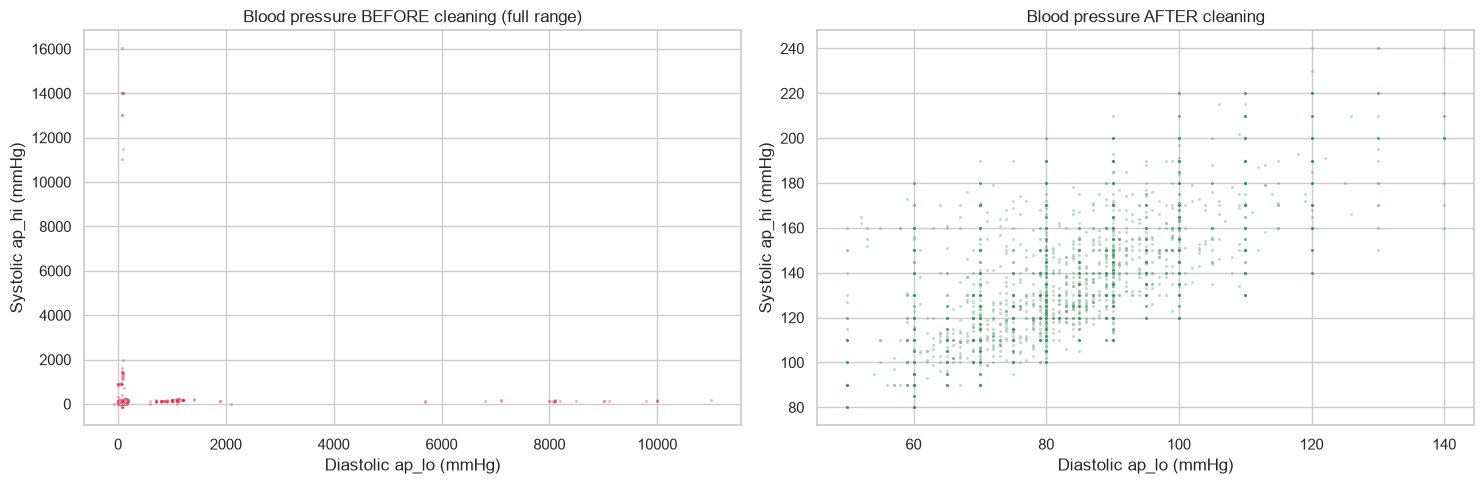

In [7]:
# Blood pressure: raw vs cleaned (the most corrupted variable)
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
sb.scatterplot(data=df, x='ap_lo', y='ap_hi', s=5, alpha=0.3, ax=ax[0], color='crimson')
ax[0].set_title('Blood pressure BEFORE cleaning (full range)')
sb.scatterplot(data=df_cleaned, x='ap_lo', y='ap_hi', s=5, alpha=0.3, ax=ax[1], color='seagreen')
ax[1].set_title('Blood pressure AFTER cleaning')
for a in ax:
    a.set_xlabel('Diastolic ap_lo (mmHg)'); a.set_ylabel('Systolic ap_hi (mmHg)')
plt.tight_layout(); plt.show()

Before cleaning, a handful of entry errors (values in the thousands, likely typos such as an extra zero) stretch the axes so far that the real data collapses into one corner and is invisible. After cleaning, a clear positive relationship between systolic and diastolic pressure appears. The vertical and horizontal stripes show that BP is mostly recorded as round numbers (e.g. 80, 90, 120), which means the measurements are coarse.

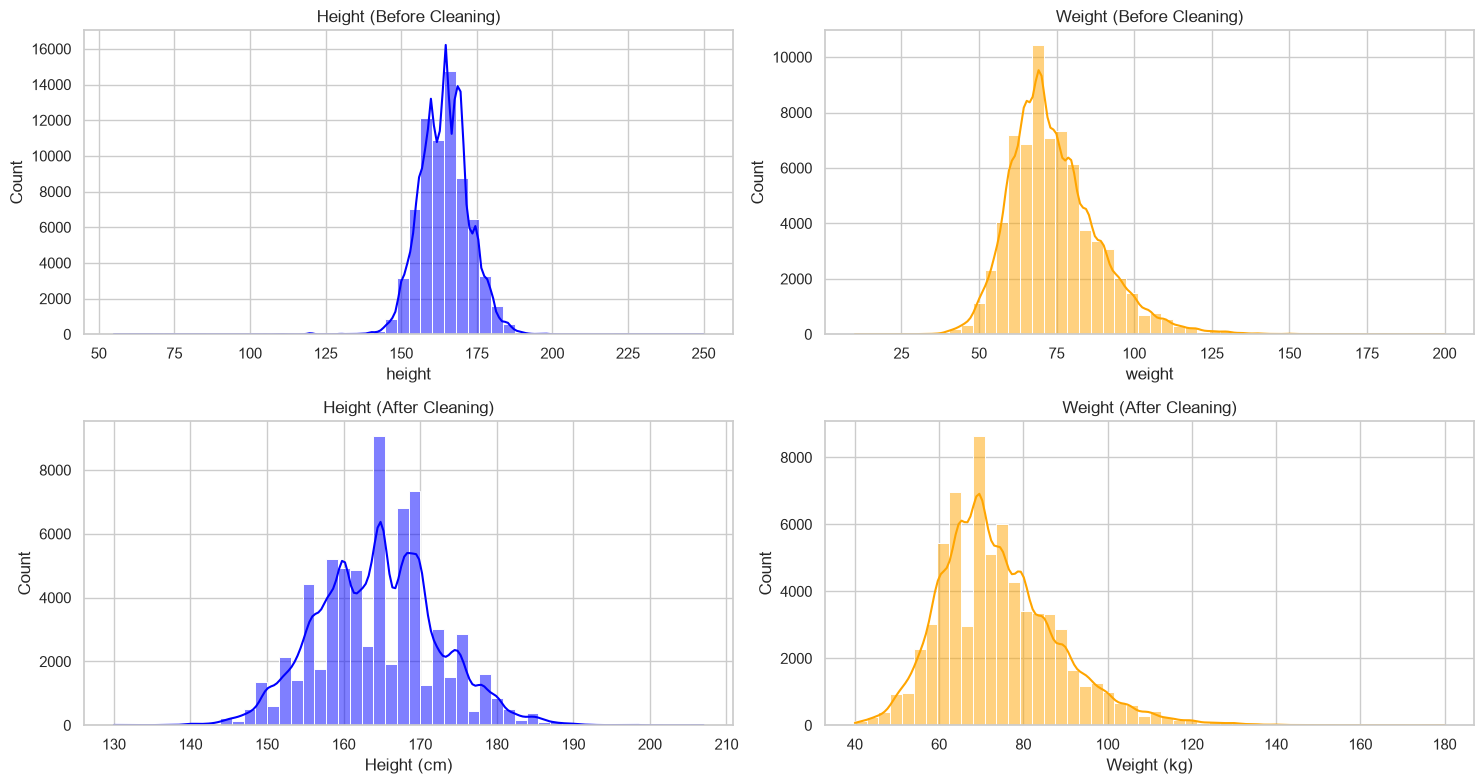

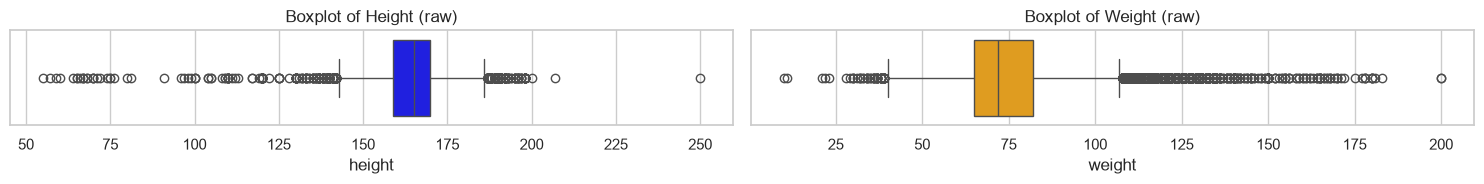

In [8]:
# Height and weight, before vs after cleaning
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
for j, (col, colr, unit) in enumerate([('height', 'blue', 'cm'), ('weight', 'orange', 'kg')]):
    sb.histplot(df[col], bins=50, kde=True, ax=ax[0, j], color=colr)
    ax[0, j].set_title(f'{col.title()} (Before Cleaning)')
    sb.histplot(df_cleaned[col], bins=50, kde=True, ax=ax[1, j], color=colr)
    ax[1, j].set_title(f'{col.title()} (After Cleaning)')
    ax[1, j].set_xlabel(f'{col.title()} ({unit})')
plt.tight_layout(); plt.show()

# Boxplots (raw)
fig, ax = plt.subplots(1, 2, figsize=(15, 2))
sb.boxplot(x=df['height'], ax=ax[0], color='blue'); ax[0].set_title('Boxplot of Height (raw)')
sb.boxplot(x=df['weight'], ax=ax[1], color='orange'); ax[1].set_title('Boxplot of Weight (raw)')
plt.tight_layout(); plt.show()

The raw histograms are squashed by extreme outliers (e.g. a 55 cm height and a 10 kg weight), and the raw boxplots show many points far from the box. After cleaning, both variables look roughly bell-shaped, as expected for adult body measurements, with weight slightly right-skewed. Cleaning removed errors without distorting the genuine distributions.

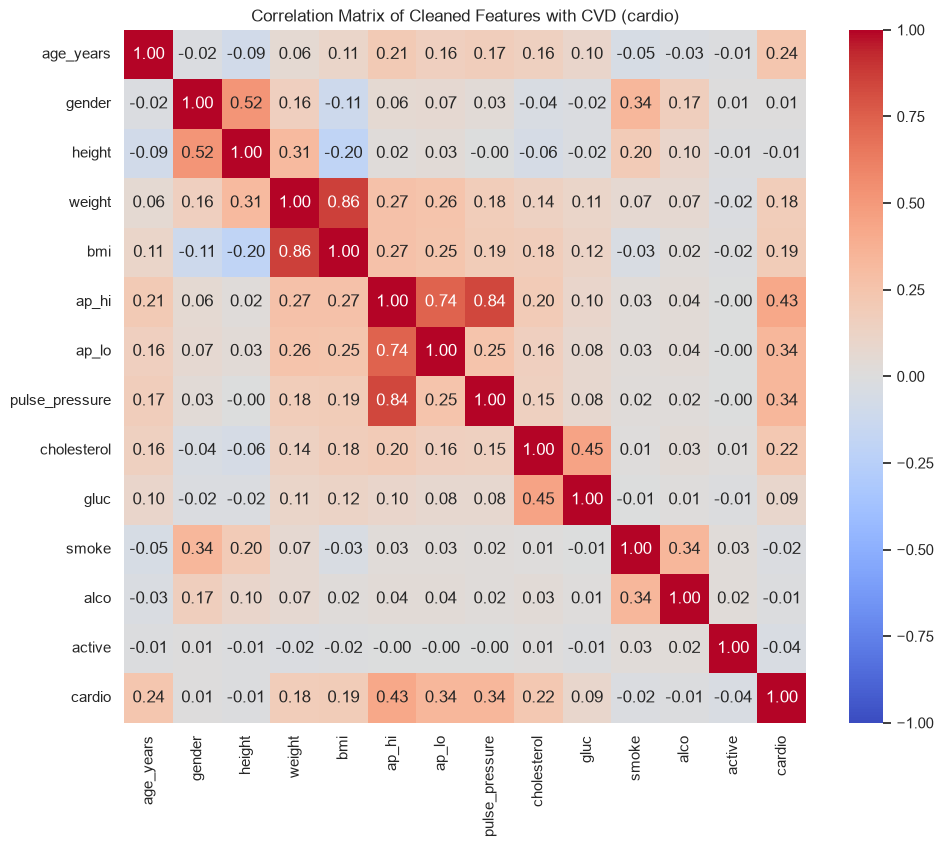

In [9]:
# Correlation Heatmap (all modelling features)
plt.figure(figsize=(11, 9))
sb.heatmap(df_cleaned[ALL_FEATURES + ['cardio']].corr(), annot=True, fmt=".2f", cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix of Cleaned Features with CVD (cardio)')
plt.show()

CVD is most correlated with systolic BP (0.43), then diastolic BP (0.34), pulse pressure (0.34), age (0.24), cholesterol (0.22), BMI (0.19) and weight (0.18). Lifestyle variables are almost uncorrelated with CVD (smoke -0.02, alco -0.01, active -0.04), and so are gender (0.01) and height (-0.01). Several predictors are strongly related to each other (e.g. weight and BMI, and ap_hi / ap_lo / pulse_pressure, since pulse pressure is their difference), which matters when interpreting SHAP later because correlated features share credit. Correlation is not causation.

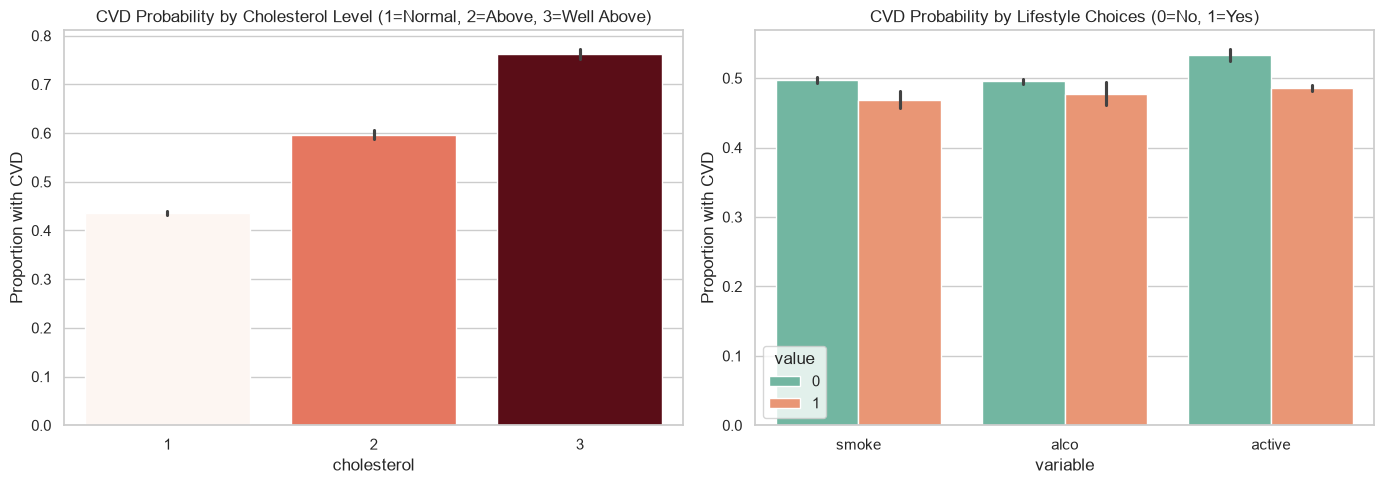

In [10]:
# CVD rate by cholesterol and by lifestyle choices
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sb.barplot(data=df_cleaned, x='cholesterol', y='cardio', hue='cholesterol', ax=axes[0], palette='Reds', legend=False)
axes[0].set_title('CVD Probability by Cholesterol Level (1=Normal, 2=Above, 3=Well Above)')
axes[0].set_ylabel('Proportion with CVD')

lifestyle_melted = df_cleaned.melt(id_vars='cardio', value_vars=['smoke', 'alco', 'active'])
sb.barplot(data=lifestyle_melted, x='variable', y='cardio', hue='value', ax=axes[1], palette='Set2')
axes[1].set_title('CVD Probability by Lifestyle Choices (0=No, 1=Yes)')
axes[1].set_ylabel('Proportion with CVD')
plt.tight_layout(); plt.show()

Cholesterol shows a clear dose-response pattern: the CVD rate is 43.5% at the normal level, 59.7% at above-normal and 76.3% at well-above-normal (75% of patients are at the normal level). Lifestyle differences are small and in places counter-intuitive: smokers (46.9% CVD) and drinkers (47.8%) have a slightly *lower* CVD rate than non-smokers (49.7%) and non-drinkers (49.6%), and active people have a rate 4.8 points lower than inactive people (48.5% vs 53.3%). The smoking result should not be read as "smoking is protective". These are self-reported yes/no answers, only 8.8% of patients report smoking and 5.3% drinking, and under-reporting and confounding are likely.

# Train / Test Split

In [11]:
# Stratified split keeps the CVD / non-CVD ratio identical in train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(f"Training data shape: {X_train.shape} | Testing data shape: {X_test.shape}")
print("CVD rate  train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Training data shape: (54672, 13) | Testing data shape: (13669, 13)
CVD rate  train: 0.4948 | test: 0.4948


# Baseline Model

In [12]:
# Baseline: Decision Tree (max_depth=5)
dt_model = DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5)
dt_model.fit(X_train, y_train)
dt_predictions = dt_model.predict(X_test)
dt_probs = dt_model.predict_proba(X_test)[:, 1]

print(f"Decision Tree Test Accuracy: {accuracy_score(y_test, dt_predictions) * 100:.2f}%")
print(f"Decision Tree Test ROC-AUC : {roc_auc_score(y_test, dt_probs):.4f}\n")
print(classification_report(y_test, dt_predictions, target_names=['No CVD', 'CVD']))

Decision Tree Test Accuracy: 73.36%
Decision Tree Test ROC-AUC : 0.7935

              precision    recall  f1-score   support

      No CVD       0.71      0.79      0.75      6905
         CVD       0.76      0.67      0.71      6764

    accuracy                           0.73     13669
   macro avg       0.74      0.73      0.73     13669
weighted avg       0.74      0.73      0.73     13669



The depth-5 Decision Tree already reaches 73.36% test accuracy and a ROC-AUC of 0.794. It is precise when it flags CVD (precision 0.76) but misses a third of real cases (CVD recall 0.67). This is the benchmark the other models must beat. The stratified split keeps the CVD share identical in the train and test sets (49.5%).

# Model Comparison and Advanced Model

In [13]:
# 5-fold cross-validated comparison on the TRAINING set (test set stays untouched)
models = {
    'Decision Tree (depth 5)': DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    'Random Forest (100 trees, depth 10)': RandomForestClassifier(n_estimators=100, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
rows = []
for name, m in models.items():
    acc = cross_val_score(m, X_train, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    auc = cross_val_score(m, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    rows.append({'Model': name, 'CV Accuracy (%)': round(acc.mean()*100, 2), 'Acc Std (%)': round(acc.std()*100, 2),
                 'CV ROC-AUC': round(auc.mean(), 4)})
cv_df = pd.DataFrame(rows)
display(cv_df)

,Model,CV Accuracy (%),Acc Std (%),CV ROC-AUC
0,Decision Tree (depth 5),72.89,0.27,0.7895
1,Logistic Regression,72.67,0.25,0.7907
2,"Random Forest (100 trees, depth 10)",73.23,0.25,0.7986
3,Hist Gradient Boosting,73.41,0.35,0.7995


All four models are close: 5-fold CV accuracy only ranges from 72.7% to 73.4% and ROC-AUC from 0.790 to 0.800. The fold-to-fold standard deviation is about 0.25-0.35 points, so the gaps between the better models are roughly the size of the noise. Even a plain Logistic Regression performs almost as well as the ensembles, so there is little non-linear structure for the extra complexity to find. Gradient Boosting and Random Forest are marginally the best on ROC-AUC.

In [14]:
# Hyper-parameter search for the Random Forest (5-fold CV inside the training set)
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [6, 8, 10, 12, 15],
    'min_samples_leaf': [1, 5, 10, 20, 40],
    'max_features': ['sqrt', 0.5, None],
}
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), param_dist,
    n_iter=15, cv=cv, scoring='roc_auc', random_state=RANDOM_STATE, n_jobs=1)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")
rf_model = search.best_estimator_

Best parameters: {'n_estimators': 200, 'min_samples_leaf': 40, 'max_features': 'sqrt', 'max_depth': 12}
Best CV ROC-AUC: 0.7990


`RandomizedSearchCV` tried 15 random Random Forest settings with 5-fold CV on the training set (the test set was not touched). It prefers strongly regularised trees (`min_samples_leaf=40`), but the best CV ROC-AUC (0.7990) is barely above the untuned forest (0.7986). Tuning gives almost no gain, another sign that the data, not the model, limits performance.

,Model,Test Accuracy (%),Test ROC-AUC,CVD Recall
0,Decision Tree,73.36,0.7935,0.673
1,Logistic Regression,72.95,0.7943,0.672
2,Random Forest (tuned),73.61,0.8035,0.689
3,Hist Gradient Boosting,73.61,0.8038,0.696


Tuned Random Forest Classification Report:
              precision    recall  f1-score   support

      No CVD       0.72      0.78      0.75      6905
         CVD       0.76      0.69      0.72      6764

    accuracy                           0.74     13669
   macro avg       0.74      0.74      0.74     13669
weighted avg       0.74      0.74      0.74     13669



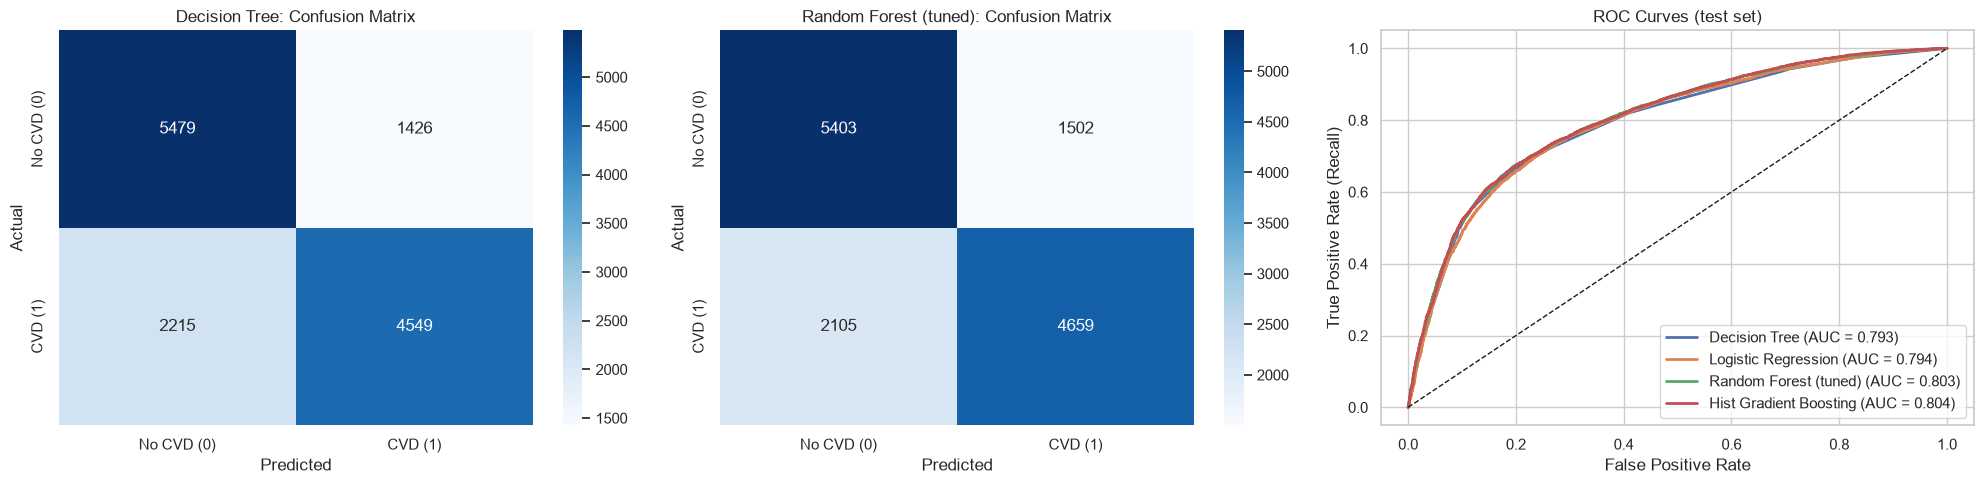

In [15]:
# Final evaluation of ALL models on the untouched test set
final = {
    'Decision Tree': dt_model,
    'Logistic Regression': models['Logistic Regression'].fit(X_train, y_train),
    'Random Forest (tuned)': rf_model,
    'Hist Gradient Boosting': models['Hist Gradient Boosting'].fit(X_train, y_train),
}
rows, rocs = [], {}
for name, m in final.items():
    p = m.predict(X_test); pr = m.predict_proba(X_test)[:, 1]
    rows.append({'Model': name, 'Test Accuracy (%)': round(accuracy_score(y_test, p)*100, 2),
                 'Test ROC-AUC': round(roc_auc_score(y_test, pr), 4),
                 'CVD Recall': round(recall_score(y_test, p), 3)})
    rocs[name] = roc_curve(y_test, pr)
test_df = pd.DataFrame(rows); display(test_df)

rf_predictions = rf_model.predict(X_test)
print("Tuned Random Forest Classification Report:")
print(classification_report(y_test, rf_predictions, target_names=['No CVD', 'CVD']))

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for a, (nm, mdl) in zip(ax[:2], [('Decision Tree', dt_model), ('Random Forest (tuned)', rf_model)]):
    cm = confusion_matrix(y_test, mdl.predict(X_test))
    sb.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=a,
               xticklabels=['No CVD (0)', 'CVD (1)'], yticklabels=['No CVD (0)', 'CVD (1)'])
    a.set_xlabel('Predicted'); a.set_ylabel('Actual'); a.set_title(f'{nm}: Confusion Matrix')
for nm, (fpr, tpr, _) in rocs.items():
    ax[2].plot(fpr, tpr, lw=2, label=f"{nm} (AUC = {test_df.set_index('Model').loc[nm,'Test ROC-AUC']:.3f})")
ax[2].plot([0, 1], [0, 1], 'k--', lw=1)
ax[2].set_xlabel('False Positive Rate'); ax[2].set_ylabel('True Positive Rate (Recall)')
ax[2].set_title('ROC Curves (test set)'); ax[2].legend()
plt.tight_layout(); plt.show()

On the untouched test set, the tuned Random Forest and Gradient Boosting tie at 73.61% accuracy (ROC-AUC 0.8035 vs 0.8038; the 0.0003 difference is noise), ahead of the Decision Tree (73.36%, AUC 0.7935) and Logistic Regression (72.95%, AUC 0.7943). The best model improves on the baseline by only about 0.25 accuracy points and 0.01 AUC. **Roughly 73-74% accuracy appears to be the ceiling for these 13 coarse features**; we should not expect any model to do much better without new information (e.g. blood tests or family history).

For the tuned Random Forest, CVD recall is 0.69: of 6,764 test patients with CVD, 2,105 (31%) were missed (false negatives), while 1,502 of 6,905 healthy patients (22%) were flagged wrongly. In a screening setting a missed case is usually worse than a false alarm, so a real deployment would lower the decision threshold to raise recall at the cost of more false alarms. We report the default 0.5 threshold and did not tune this. The ROC curves for all four models almost overlap.

In [16]:
# Feature-group ablation: how much can each TYPE of factor predict on its own?
# Uses the SAME FEATURE_GROUPS as the SHAP analysis below.
abl_rows = []
subsets = {**{g: c for g, c in FEATURE_GROUPS.items()}, 'All Combined Features': ALL_FEATURES}
for name, cols in subsets.items():
    m = RandomForestClassifier(**{**rf_model.get_params(), 'n_jobs': -1}).fit(X_train[cols], y_train)
    p = m.predict(X_test[cols]); pr = m.predict_proba(X_test[cols])[:, 1]
    abl_rows.append({'Feature Group': name, 'No. Features': len(cols),
                     'Accuracy (%)': round(accuracy_score(y_test, p)*100, 2),
                     'ROC-AUC': round(roc_auc_score(y_test, pr), 4)})
results_df = pd.DataFrame(abl_rows); display(results_df)

,Feature Group,No. Features,Accuracy (%),ROC-AUC
0,Immutable Traits,3,59.82,0.6386
1,Physiological Vitals,7,72.70,0.7806
2,Lifestyle Choices,3,51.39,0.5148
3,All Combined Features,13,73.61,0.8035


Using the same group definitions as the SHAP analysis below: Physiological Vitals alone reach 72.70% accuracy (AUC 0.781), within 0.9 points of the full model (73.61%, AUC 0.8035). Immutable traits alone are much weaker (59.82%, AUC 0.639). **Lifestyle alone is at chance level** (51.39%, AUC 0.515; always predicting "no CVD" would score 50.5%). So, in this dataset, measured physiology carries nearly all of the predictive signal, and the lifestyle questions add almost nothing.

# SHAP (SHapley Additive exPlanation)

SHAP Feature Importance (Bar Chart)


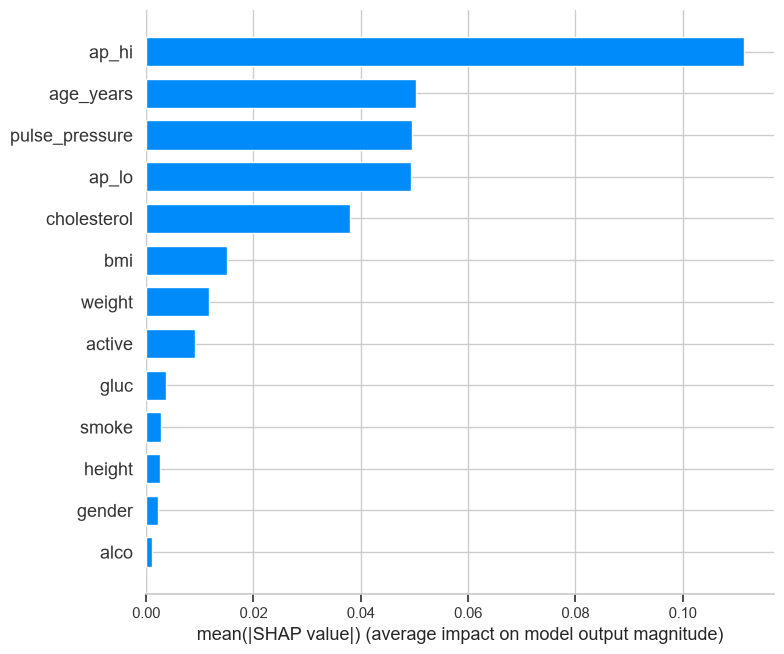

SHAP Detailed Summary Plot


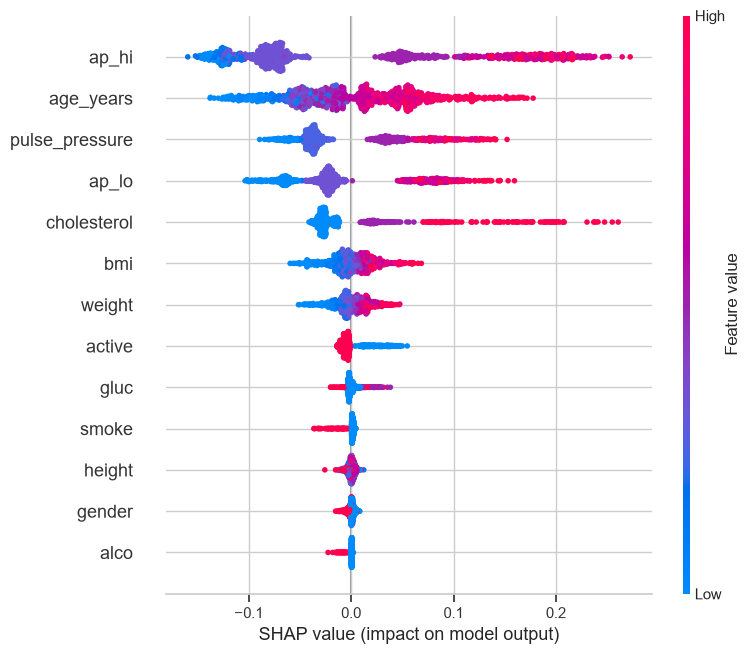

In [17]:
# Explain the tuned Random Forest on a 1000-row sample of the test set
explainer = shap.TreeExplainer(rf_model)
X_test_sample = X_test.sample(n=1000, random_state=RANDOM_STATE)
shap_values = explainer.shap_values(X_test_sample)

# Handle different versions of the SHAP library
if isinstance(shap_values, list):
    shap_values_cvd = shap_values[1]
else:
    shap_values_cvd = shap_values[:, :, 1]

print("SHAP Feature Importance (Bar Chart)")
shap.summary_plot(shap_values_cvd, X_test_sample, plot_type="bar")
print("SHAP Detailed Summary Plot")
shap.summary_plot(shap_values_cvd, X_test_sample)

SHAP explains the tuned Random Forest's predictions for CVD (class 1) on a random sample of 1,000 test patients. In the beeswarm plot, red points (high feature values) for `ap_hi`, `ap_lo`, `pulse_pressure`, `age_years` and `cholesterol` sit on the right (pushing the prediction towards CVD), while low values push it to the left. Features such as `alco`, `smoke`, `gender` and `height` have points tightly clustered around zero, meaning they barely change predictions. Note that "yes" for `smoke`, `alco` and `active` all nudge the CVD prediction slightly *down*, consistent with the counter-intuitive smoking/alcohol pattern seen in the EDA (self-reporting and confounding, not a protective effect).

,Category,Mean_Abs_SHAP,Percentage_Share (%)
2,Physiological Vitals,0.278748,80.39
0,Immutable Traits,0.054994,15.86
1,Lifestyle Choices,0.012985,3.74


,Feature,Category,Share (%)
0,ap_hi,Physiological Vitals,32.1
1,age_years,Immutable Traits,14.5
2,pulse_pressure,Physiological Vitals,14.3
3,ap_lo,Physiological Vitals,14.2
4,cholesterol,Physiological Vitals,10.9
5,bmi,Physiological Vitals,4.3
6,weight,Physiological Vitals,3.4
7,active,Lifestyle Choices,2.6
8,gluc,Physiological Vitals,1.1
9,smoke,Lifestyle Choices,0.8


Combined share of the three blood-pressure features (ap_hi, ap_lo, pulse_pressure): 60.6%


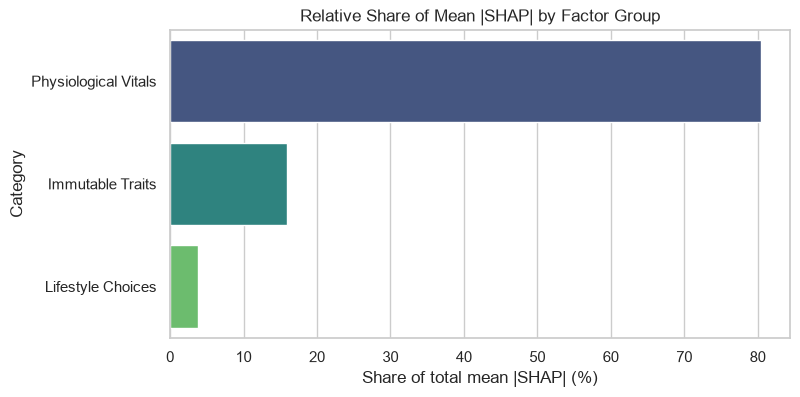

In [18]:
# Group SHAP values using the SAME FEATURE_GROUPS mapping as the ablation study
mean_abs_shap = np.abs(shap_values_cvd).mean(axis=0)
shap_df = pd.DataFrame({'Feature': X_test_sample.columns, 'Mean_Abs_SHAP': mean_abs_shap})
shap_df['Category'] = shap_df['Feature'].map(CATEGORY_OF)

grouped_shap = shap_df.groupby('Category')['Mean_Abs_SHAP'].sum().reset_index()
grouped_shap['Percentage_Share (%)'] = (grouped_shap['Mean_Abs_SHAP'] / grouped_shap['Mean_Abs_SHAP'].sum() * 100).round(2)
grouped_shap = grouped_shap.sort_values(by='Percentage_Share (%)', ascending=False)
display(grouped_shap)

# Per-feature share of total mean |SHAP|
shap_df['Share (%)'] = (shap_df['Mean_Abs_SHAP'] / shap_df['Mean_Abs_SHAP'].sum() * 100).round(1)
display(shap_df.sort_values('Mean_Abs_SHAP', ascending=False)[['Feature', 'Category', 'Share (%)']].reset_index(drop=True))
bp_share = shap_df[shap_df['Feature'].isin(['ap_hi', 'ap_lo', 'pulse_pressure'])]['Share (%)'].sum()
print(f"Combined share of the three blood-pressure features (ap_hi, ap_lo, pulse_pressure): {bp_share:.1f}%")

plt.figure(figsize=(8, 4))
sb.barplot(data=grouped_shap, x='Percentage_Share (%)', y='Category', hue='Category', palette='viridis', legend=False)
plt.title("Relative Share of Mean |SHAP| by Factor Group")
plt.xlabel("Share of total mean |SHAP| (%)")
plt.show()

Physiological Vitals account for 80.4% of the model's total mean |SHAP|, Immutable Traits for 15.9% and Lifestyle Choices for 3.7%. Systolic BP alone is the single largest feature (about a third of the total), and the three blood-pressure features together make up about 60%. This agrees with the ablation, where vitals alone nearly matched the full model and lifestyle alone was at chance.

**Caveats:**
- These are *relative shares of how much the model relies on each feature*, not the share of disease caused by each factor, and they do **not** show causation.
- Correlated features split credit (e.g. `ap_hi`, `ap_lo` and `pulse_pressure` are mathematically linked; `weight` and `bmi` too), so individual feature shares are less stable than group totals.
- The lifestyle variables are self-reported yes/no answers with very few "yes" cases for smoking and alcohol. Their low importance may partly reflect how coarsely they are measured rather than a true absence of health effects.
- Weight and BMI are placed under Physiological Vitals because they are measured body properties, even though they are partly shaped by lifestyle. Group shares depend on this choice.
- SHAP was computed on a 1,000-row sample for speed.

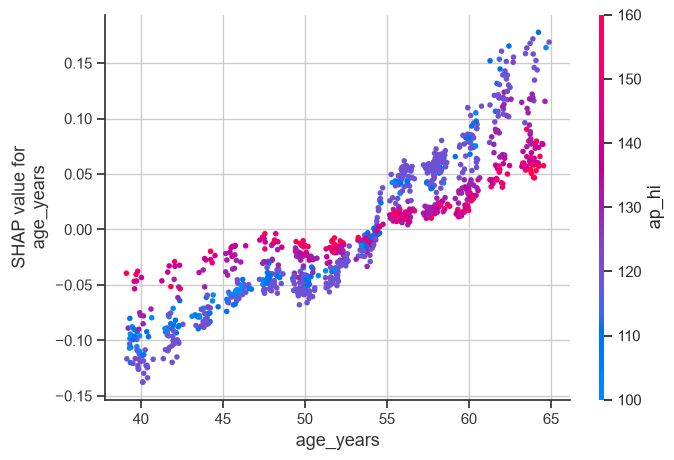

In [19]:
# SHAP dependence plot: age effect, coloured by systolic BP
shap.dependence_plot("age_years", shap_values_cvd, X_test_sample, interaction_index="ap_hi")

The model's age contribution rises steadily with age: it lowers the CVD prediction for patients in their early 40s and raises it for patients in their early 60s, with a visible step up around age 54-55. The colouring shows that at the same age, patients with higher systolic BP tend to get a *lower* age contribution. Age and BP are correlated, so the model shares credit between them, and this plot should be read as a description of the model, not as a biological interaction.

# Conclusion, Limitations and Clinical Note

## Conclusion
- **Prediction:** routine measurements predict CVD with about **73.6% accuracy and ROC-AUC about 0.80**. A tuned Random Forest and Gradient Boosting performed about equally, and both beat the Decision Tree baseline only slightly. The limiting factor is the information in the features, not the choice of model.
- **Explanation:** measured physiology, above all blood pressure, drives the predictions (about 80% of SHAP importance, and vitals alone almost match the full model). Immutable traits, mainly age, contribute about 16%. Self-reported lifestyle contributes under 4% and has no predictive power on its own.

## Limitations
- Cross-sectional data: the model finds associations, not causes, and cannot say whether changing a lifestyle habit would change risk.
- Self-reported, binary lifestyle variables and coarse BP readings (mostly round numbers); the dataset's collection method is not documented.
- Our cleaning thresholds are judgement calls; 2.37% of rows were removed.
- The default 0.5 decision threshold gives 69% recall, which is too low for a screening tool without further threshold tuning.
- This is an educational project, not a clinical tool.

## Possible extensions
Tune the decision threshold for higher recall, add a calibration check, try permutation importance as a cross-check on SHAP, and test on an external dataset.